In [25]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import os

# Go one level up from the current working directory
ROOT_DIR = os.path.dirname(os.getcwd())

#Build Path
DATA_DIR = os.path.join(ROOT_DIR, "data", "raw")

# Load datasets
train = pd.read_parquet(os.path.join(DATA_DIR, "train.parquet"))
#test = pd.read_parquet(os.path.join(DATA_DIR, "test.parquet"))

# EDA

## Introduction to the dataset 

In [26]:
train.sample(5)

,status,gender,firstName,level,lastName,userId,ts,auth,page,sessionId,location,itemInSession,userAgent,method,length,song,artist,time,registration
23047601,200,F,Gwen,paid,Smith,1897423,1538618217000,Logged In,NextSong,5927,"Erie, PA",38,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_10)...",PUT,232.80281,Cadillac,Andrew W.K.,2018-10-04 01:56:57,2018-07-25 18:57:39
4680896,200,F,Stephanie,free,Lee,1199908,1539618580000,Logged In,NextSong,72486,"Los Angeles-Long Beach-Anaheim, CA",20,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_4...",PUT,200.38485,Lesson,Fu Manchu,2018-10-15 15:49:40,2018-08-10 12:40:08
8951150,200,M,Daniel,paid,Velasquez,1327222,1540654706000,Logged In,Add to Playlist,125014,"Houston-The Woodlands-Sugar Land, TX",82,Mozilla/5.0 (Windows NT 6.3; WOW64; rv:31.0) G...,PUT,NaN,None,None,2018-10-27 15:38:26,2018-09-26 21:32:32
10279108,200,F,Lily,paid,West,1110476,1541007165000,Logged In,NextSong,139914,"Chicago-Naperville-Elgin, IL-IN-WI",77,"""Mozilla/5.0 (iPad; CPU OS 7_1_2 like Mac OS X...",PUT,295.67955,Pursuit Of Happiness (nightmare),Kid Cudi / MGMT / Ratatat,2018-10-31 17:32:45,2018-06-05 22:59:17
14793603,200,F,Josselyn,paid,Webb,1367118,1542200868000,Logged In,NextSong,174083,"New York-Newark-Jersey City, NY-NJ-PA",274,"""Mozilla/5.0 (iPhone; CPU iPhone OS 7_1_1 like...",PUT,195.05587,Sorry County Blues,Lonesome River Band,2018-11-14 13:07:48,2018-09-01 23:34:12


In [27]:
train.shape

# Dataset is composed of 17,499,636 observations of 19 features

(17499636, 19)

In [28]:
train.describe()

,status,ts,sessionId,itemInSession,length,time,registration
count,1.749964e+07,1.749964e+07,1.749964e+07,1.749964e+07,1.429143e+07,17499636,17499636
mean,2.091387e+02,1.540428e+12,8.480294e+04,1.055937e+02,2.487135e+02,2018-10-25 00:47:01.161927,2018-08-25 04:40:21.543066
min,2.000000e+02,1.538352e+12,1.000000e+00,0.000000e+00,5.220000e-01,2018-10-01 00:00:01,2017-10-14 22:05:25
25%,2.000000e+02,1.539340e+12,2.515900e+04,2.600000e+01,1.998885e+02,2018-10-12 10:33:57.750000,2018-08-10 21:14:59
50%,2.000000e+02,1.540397e+12,7.903800e+04,6.600000e+01,2.340828e+02,2018-10-24 15:58:54,2018-09-05 18:35:50
75%,2.000000e+02,1.541500e+12,1.383680e+05,1.440000e+02,2.768714e+02,2018-11-06 10:25:35,2018-09-20 17:24:57
max,4.040000e+02,1.542672e+12,2.070030e+05,1.426000e+03,3.024666e+03,2018-11-20 00:00:00,2018-11-19 23:34:34
std,3.023050e+01,1.233485e+09,6.141427e+04,1.168854e+02,9.722845e+01,NaN,NaN


In [29]:
# Checking for missing values by columns
train.isna().sum()

# We observe that all missing values are located either length, song or artist with total 3,208,203 missing values


status                 0
gender                 0
firstName              0
level                  0
lastName               0
userId                 0
ts                     0
auth                   0
page                   0
sessionId              0
location               0
itemInSession          0
userAgent              0
method                 0
length           3208203
song             3208203
artist           3208203
time                   0
registration           0
dtype: int64

In [30]:
train[train["song"].isna()].sample(3)
# These 3,208,203 missing values correspond to all the logs where page wasn't related to listening music
# No need to drop them !

,status,gender,firstName,level,lastName,userId,ts,auth,page,sessionId,location,itemInSession,userAgent,method,length,song,artist,time,registration
14358239,307,F,Amarra,paid,Patrick,1016471,1542100478000,Logged In,Thumbs Up,153637,"Ogden-Clearfield, UT",151,Mozilla/5.0 (Macintosh; Intel Mac OS X 10.8; r...,PUT,NaN,None,None,2018-11-13 09:14:38,2018-07-03 14:39:08
13304519,200,F,Lilliana,paid,Cunningham,1810363,1541781148000,Logged In,Add to Playlist,175098,"Alpena, MI",21,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_4...",PUT,NaN,None,None,2018-11-09 16:32:28,2018-09-20 00:16:19
6936096,307,F,Sarah,paid,Ortiz,1291501,1540190233000,Logged In,Thumbs Up,95177,"Trenton, NJ",5,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:31.0) G...,PUT,NaN,None,None,2018-10-22 06:37:13,2018-08-16 07:19:57


In [31]:
# Users are identified by their UserID, one UserID usually has multiple logs
print("Number of unique users:",f"{train['userId'].nunique():,}")

# Example : sample of the 10 first logs of user 1488695
train[train['userId']=='1488695'].sort_values(by='time').sample(10)

Number of unique users: 19,140


,status,gender,firstName,level,lastName,userId,ts,auth,page,sessionId,location,itemInSession,userAgent,method,length,song,artist,time,registration
3679443,200,M,Andrey,paid,Hill,1488695,1539314929000,Logged In,NextSong,72187,"McAllen-Edinburg-Mission, TX",48,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,206.65424,The Fear,Lily Allen,2018-10-12 03:28:49,2018-08-15 06:04:59
3351045,200,M,Andrey,paid,Hill,1488695,1539240641000,Logged In,NextSong,66477,"McAllen-Edinburg-Mission, TX",134,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,308.68853,New Age Music,Pat Travers,2018-10-11 06:50:41,2018-08-15 06:04:59
3564104,200,M,Andrey,paid,Hill,1488695,1539288109000,Logged In,NextSong,69569,"McAllen-Edinburg-Mission, TX",23,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,156.21179,Cemetary Party,Air,2018-10-11 20:01:49,2018-08-15 06:04:59
5439218,200,M,Andrey,free,Hill,1488695,1539789487000,Logged In,NextSong,90546,"McAllen-Edinburg-Mission, TX",44,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,217.33832,No One's Gonna Love You (Album),Band Of Horses,2018-10-17 15:18:07,2018-08-15 06:04:59
16085317,200,M,Andrey,paid,Hill,1488695,1542560348000,Logged In,NextSong,202296,"McAllen-Edinburg-Mission, TX",101,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,192.83546,Heartbreaker,MSTRKRFT / John Legend,2018-11-18 16:59:08,2018-08-15 06:04:59
4011688,200,M,Andrey,paid,Hill,1488695,1539389312000,Logged In,NextSong,73475,"McAllen-Edinburg-Mission, TX",124,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,235.93751,Crazy In Love,BeyoncÃÂ© feat. Jay-Z,2018-10-13 00:08:32,2018-08-15 06:04:59
11331039,200,M,Andrey,free,Hill,1488695,1541264934000,Logged In,NextSong,152991,"McAllen-Edinburg-Mission, TX",78,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,238.62812,Dear Vienna,Owl City,2018-11-03 17:08:54,2018-08-15 06:04:59
6429240,200,M,Andrey,free,Hill,1488695,1540002744000,Logged In,About,97966,"McAllen-Edinburg-Mission, TX",26,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",GET,NaN,None,None,2018-10-20 02:32:24,2018-08-15 06:04:59
382905,200,M,Andrey,paid,Hill,1488695,1538464569000,Logged In,NextSong,30448,"McAllen-Edinburg-Mission, TX",18,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,233.63873,Frente A Frente,Bunbury,2018-10-02 07:16:09,2018-08-15 06:04:59
13683671,200,M,Andrey,paid,Hill,1488695,1541898989000,Logged In,NextSong,179234,"McAllen-Edinburg-Mission, TX",51,"""Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_3...",PUT,253.62240,Losing Touch,The Killers,2018-11-11 01:16:29,2018-08-15 06:04:59


### Train-test consistency 

We examine the temporal coverage of both datasets and check whether users appear in both sets.

In [32]:
# Read only the necessary columns from the test set.
test_events = pd.read_parquet(
    os.path.join(DATA_DIR, "test.parquet"),
    columns=["userId", "ts", "page"],
)

train_ids = set(train["userId"].dropna().unique())
test_ids = set(test_events["userId"].dropna().unique())

print("Train users:", len(train_ids))
print("Test users:", len(test_ids))
print("Users in both datasets:", len(train_ids.intersection(test_ids)))

print("Train date range:", pd.to_datetime(train["ts"].min(), unit="ms"),
      "to", pd.to_datetime(train["ts"].max(), unit="ms"))
print("Test date range:", pd.to_datetime(test_events["ts"].min(), unit="ms"),
      "to", pd.to_datetime(test_events["ts"].max(), unit="ms"))


Train users: 19140
Test users: 2904
Users in both datasets: 0
Train date range: 2018-10-01 00:00:01 to 2018-11-20 00:00:00
Test date range: 2018-10-01 00:00:06 to 2018-11-20 00:00:00


**Findings:** Both datasets cover the same observation period (October 1–November 20, 2018), but contain distinct users: 19,140 in the training set and 2,904 in the test set, with no overlap. 

These findings support a validation strategy based on separate groups of users.

In [33]:
# We identify the target variable "Cancellation Confirmation" & "Cancel"

train["page"].value_counts()

page
NextSong                     14291433
Thumbs Up                      789391
Home                           645259
Add to Playlist                409606
Roll Advert                    284837
Add Friend                     262147
Logout                         204700
Thumbs Down                    164964
Downgrade                      124248
Settings                       101191
Help                            89035
Upgrade                         37696
About                           33117
Save Settings                   20370
Error                           17294
Submit Upgrade                  11381
Submit Downgrade                 4425
Cancellation Confirmation        4271
Cancel                           4271
Name: count, dtype: int64

In [34]:
# "Auth" also seems to be a proxy for Churn, learning on this variable could be detrimental
train["auth"].value_counts()

auth
Logged In    17495365
Cancelled        4271
Name: count, dtype: int64

In [35]:
# Computing the number of users having only used the free version, only the paid version, and the free + paid version

user_types = train.groupby('userId')['level'].agg(
    lambda x: set(x.dropna())
)

# User classification
print(f"Free subscription only: {user_types.apply(lambda x: x == {'free'}).sum():,}")
print(f"Paid subscription only: {user_types.apply(lambda x: x == {'paid'}).sum():,}")
print(f"Both: {user_types.apply(lambda x: x == {'free', 'paid'}).sum():,}")

# the numbers below correctly add up to retrieve the number of unique users : 19,140

Free subscription only: 5,963
Paid subscription only: 3,158
Both: 10,019


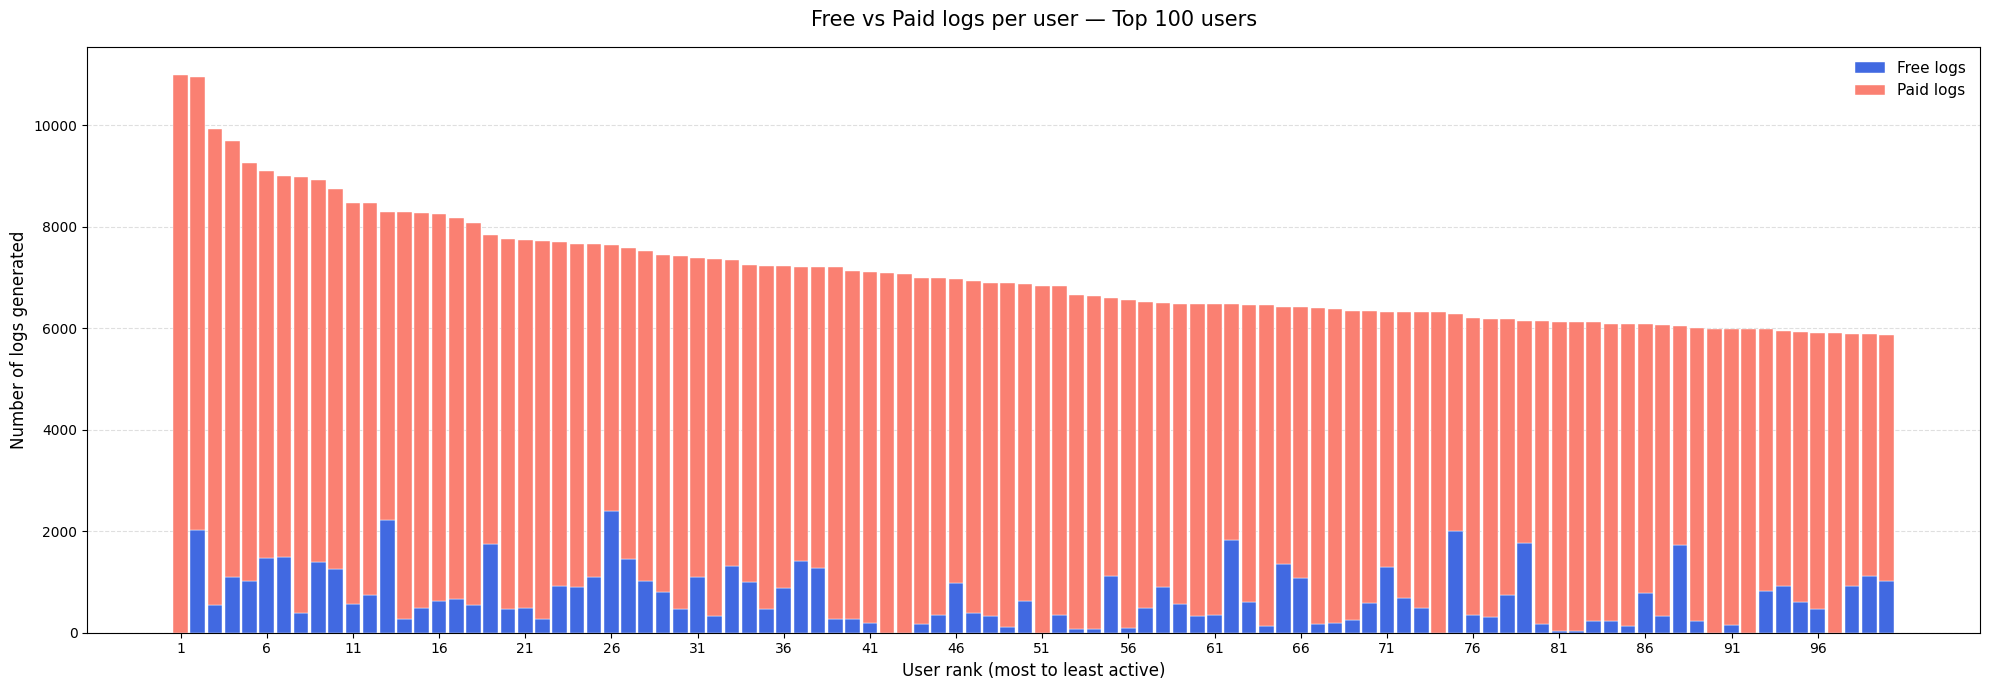

In [36]:
import matplotlib.pyplot as plt
import numpy as np

# Count logs per user and subscription type
df_users = (
    train.groupby(['userId', 'level'])
    .size()
    .unstack(fill_value=0)
)

# Rank users by total logs
df_users['totalLogs'] = df_users['free'] + df_users['paid']
df_users = df_users.sort_values('totalLogs', ascending=False)

# Keep top 100 users
df_plot = df_users.head(100)

# Plot
fig, ax = plt.subplots(figsize=(20, 7))

x = np.arange(1, len(df_plot) + 1)

ax.bar(x, df_plot['free'], width=0.85, color='royalblue',
       label='Free logs', edgecolor='white', linewidth=0.3)

ax.bar(x, df_plot['paid'], width=0.85, bottom=df_plot['free'],
       color='salmon', label='Paid logs',
       edgecolor='white', linewidth=0.3)

ax.set_xlabel('User rank (most to least active)', fontsize=12)
ax.set_ylabel('Number of logs generated', fontsize=12)
ax.set_title('Free vs Paid logs per user — Top 100 users',
             fontsize=15, pad=15)

ax.set_xticks(np.arange(1, 101, 5))
ax.tick_params(axis='both', labelsize=10)

ax.grid(axis='y', linestyle='--', alpha=0.4)
ax.set_axisbelow(True)

ax.legend(fontsize=11, frameon=False)

plt.tight_layout()
plt.show()

In [37]:
# We see that users switching from free to paid subscription substantially increase the use of the streaming service
# Churners could surepresented be among the users that did not decide to switch to paid subscription
# or downgraded from paid to free program

## Defining Churn target 

In [38]:
# Isolating the target variable in Churn (boolean True or False)

train["Churn"] = (train["page"]=="Cancellation Confirmation")

In [39]:
print("Number of Churners:",f"{train['Churn'].sum():,}")
print("Number of Non-Churners",f"{(train['userId'].nunique()) - (train['Churn'].sum()):,}")
print(f"Overall observed churn rate: {train['Churn'].sum() / train['userId'].nunique():.2%}")
print("Number of logs not related to Churning", f"{train.shape[0]-(train['Churn'].sum()):,}")

# The number of users churning is low compared to the number of users who do not (1:3) and
# even lower when considering the number of logs concerning the cancellation (4k vs 17,5 M).
# This hints a possible class imbalance when it will come to predictions (more likely to predict non churners (0))

# Hence the need to use the balanced accuracy, as demanded by the subject : the balanced accuracy gives equal importance to
# the number of correct predictions of 0 and 1. This is relevant as in this case, predicting mostly 0 could yield a very high
# accuracy as most client do not resign their subscription but it is clear that the company is economically much more interested
# to accurately predict the potential churners to try to keep them in !

Number of Churners: 4,271
Number of Non-Churners 14,869
Overall observed churn rate: 22.31%
Number of logs not related to Churning 17,495,365


In [40]:
train["page"].value_counts()

page
NextSong                     14291433
Thumbs Up                      789391
Home                           645259
Add to Playlist                409606
Roll Advert                    284837
Add Friend                     262147
Logout                         204700
Thumbs Down                    164964
Downgrade                      124248
Settings                       101191
Help                            89035
Upgrade                         37696
About                           33117
Save Settings                   20370
Error                           17294
Submit Upgrade                  11381
Submit Downgrade                 4425
Cancellation Confirmation        4271
Cancel                           4271
Name: count, dtype: int64

In [41]:
# Let's redefine Churn more granularly

train = train.drop(columns="Churn")

# Let's make the distinction between churning event and downgrade event (observation level)
# and the churn and downgrade, marking all user's logs as of a churner/ downgrader (userID level)

# 1. Create binary event indicators
train['churn_event'] = (
    train['page'] == 'Cancellation Confirmation'
)

train['downgrade_event'] = (
    train['page'] == 'Submit Downgrade'
)

# 2. Propagate events to all observations of each user
train['churn'] = train.groupby('userId')['churn_event'].transform('max')

train['downgrade'] = train.groupby('userId')['downgrade_event'].transform('max')

train.head()

,status,gender,firstName,level,lastName,userId,ts,auth,page,sessionId,...,method,length,song,artist,time,registration,churn_event,downgrade_event,churn,downgrade
0,200,M,Shlok,paid,Johnson,1749042,1538352001000,Logged In,NextSong,22683,...,PUT,524.32934,Ich mache einen Spiegel - Dream Part 4,Popol Vuh,2018-10-01 00:00:01,2018-08-08 13:22:21,False,False,True,False
992,200,M,Shlok,paid,Johnson,1749042,1538352525000,Logged In,NextSong,22683,...,PUT,178.02404,Monster (Album Version),Skillet,2018-10-01 00:08:45,2018-08-08 13:22:21,False,False,True,False
1360,200,M,Shlok,paid,Johnson,1749042,1538352703000,Logged In,NextSong,22683,...,PUT,232.61995,Seven Nation Army,The White Stripes,2018-10-01 00:11:43,2018-08-08 13:22:21,False,False,True,False
1825,200,M,Shlok,paid,Johnson,1749042,1538352935000,Logged In,NextSong,22683,...,PUT,265.50812,Under The Bridge (Album Version),Red Hot Chili Peppers,2018-10-01 00:15:35,2018-08-08 13:22:21,False,False,True,False
2366,200,M,Shlok,paid,Johnson,1749042,1538353200000,Logged In,NextSong,22683,...,PUT,471.69261,Circlesong 6,Bobby McFerrin,2018-10-01 00:20:00,2018-08-08 13:22:21,False,False,True,False


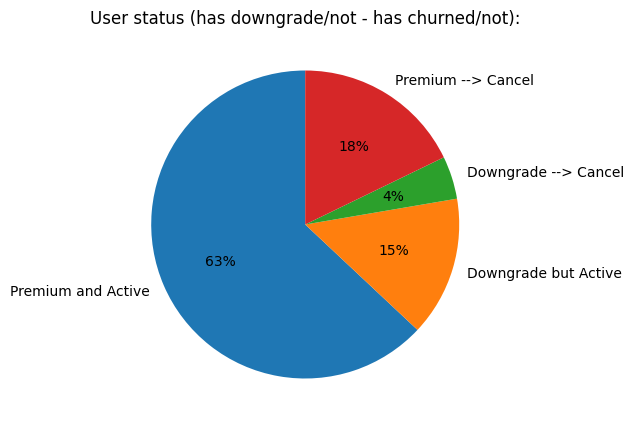

{'Premium and Active': np.int64(12059), 'Downgrade but Active': np.int64(2810), 'Downgrade --> Cancel': np.int64(861), 'Premium --> Cancel': np.int64(3410)}


In [42]:
import matplotlib.pyplot as plt

# One row per user
users = train.drop_duplicates('userId')

subjects = [
    'Premium and Active',
    'Downgrade but Active',
    'Downgrade --> Cancel',
    'Premium --> Cancel'
]

data = [
    ((users['downgrade'] == 0) & (users['churn'] == 0)).sum(),
    ((users['downgrade'] == 1) & (users['churn'] == 0)).sum(),
    ((users['downgrade'] == 1) & (users['churn'] == 1)).sum(),
    ((users['downgrade'] == 0) & (users['churn'] == 1)).sum()
]

fig, ax = plt.subplots(figsize=(5, 5))

ax.pie(
    data,
    labels=subjects,
    autopct='%1.0f%%',
    startangle=90
)

ax.set_title('User status (has downgrade/not - has churned/not):')

plt.show()

print(dict(zip(subjects, data)))

# This pie chart suggests that quite a large part of the users downgrading their subscription
# still decide to keep their account and use the platform

# Be careful, this pie chart does not include the Free users Active, only the former Premium Active (15%)

### Churn over a 10-day horizon

The previous analysis identifies users who cancelled at some point during the observation period. For the competition, however, we need to predict whether a user will cancel within the next 10 days.

To investigate this, we use three historical cutoff dates: October 21, October 31, and November 10. For each cutoff, we select users who have already appeared and have not previously cancelled, then determine whether they cancel during the following 10 days.

We start by comparing the number of eligible users and the churn rate across these dates.

In [43]:
# One first event and at most one first cancellation per user.
first_seen_ts = train.groupby("userId")["ts"].min()
first_cancel_ts = (
    train.loc[train["page"].eq("Cancellation Confirmation")]
    .groupby("userId")["ts"]
    .min()
    .reindex(first_seen_ts.index)
)

DAY_MS = 24 * 60 * 60 * 1000
HORIZON_MS = 10 * DAY_MS
CUTOFF_DATES = ["2018-10-21", "2018-10-31", "2018-11-10"]

cutoff_rows = []
for date in CUTOFF_DATES:
    t = int(pd.Timestamp(date, tz="UTC").timestamp() * 1000)

    # Eligibility and targets use mutually exclusive time intervals.
    eligible = first_seen_ts.lt(t) & (
        first_cancel_ts.isna() | first_cancel_ts.ge(t)
    )
    churn_next_10d = first_cancel_ts.ge(t) & first_cancel_ts.lt(
        t + HORIZON_MS
    )

    n_users = int(eligible.sum())
    n_churners = int((eligible & churn_next_10d).sum())
    cutoff_rows.append({
        "cutoff": date,
        "eligible_users": n_users,
        "churners_next_10d": n_churners,
        "churn_rate_pct": 100 * n_churners / n_users,
    })

cutoff_summary = pd.DataFrame(cutoff_rows)
display(cutoff_summary.round(2))

,cutoff,eligible_users,churners_next_10d,churn_rate_pct
0,2018-10-21,15452,817,5.29
1,2018-10-31,15530,789,5.08
2,2018-11-10,15276,663,4.34


## User engagement before churn

### Recent activity levels

We first investigate whether recent user engagement is associated with subsequent churn.

For each historical cutoff, we compare the number of events and songs played during the previous seven days between users who will cancel within the next 10 days and those who will remain subscribed.

This allows us to examine whether differences in engagement are consistent across observation periods.

,cutoff,churn_10d,n_users,mean_songs,median_songs,mean_events,median_events
0,2018-10-21,0,14635,124.29,47.0,152.11,61.0
1,2018-10-21,1,817,225.21,134.0,275.45,170.0
2,2018-10-31,0,14741,119.44,42.0,145.60,54.0
3,2018-10-31,1,789,235.04,130.0,284.94,162.0
4,2018-11-10,0,14613,112.96,36.0,137.46,47.0
5,2018-11-10,1,663,216.73,141.0,261.59,175.0


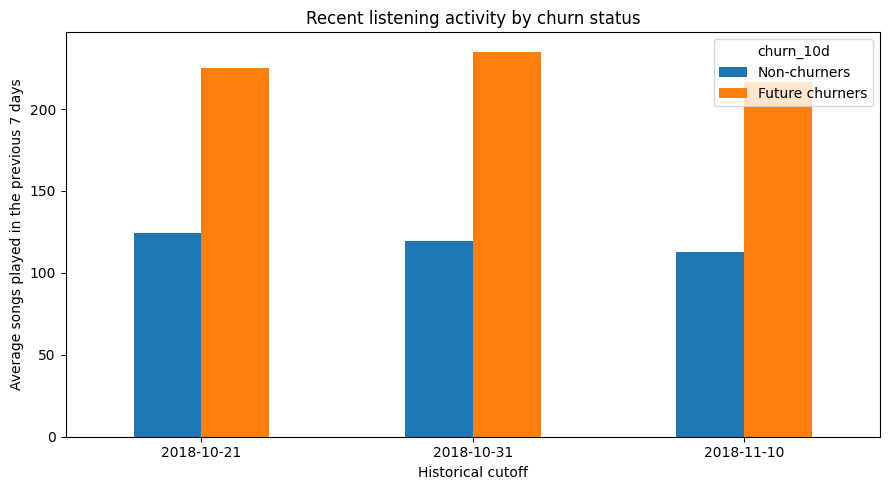

In [46]:
# Build user-level activity indicators for each historical cutoff
rows = []

for cutoff_date in CUTOFF_DATES:
    t = int(pd.Timestamp(cutoff_date, tz="UTC").timestamp() * 1000)

    # Select users who have not cancelled before the cutoff
    eligible = first_seen_ts.lt(t) & (
        first_cancel_ts.isna() | first_cancel_ts.ge(t)
    )
    user_ids = first_seen_ts.index[eligible]

    # Only use events from the previous seven days
    recent = train.loc[
        train["ts"].ge(t - 7 * DAY_MS) & train["ts"].lt(t),
        ["userId", "page"]
    ]

    page_counts = (
        recent.groupby(["userId", "page"])
        .size()
        .unstack(fill_value=0)
    )

    # Determine churn during the following 10 days
    cancel_dates = first_cancel_ts.reindex(user_ids)

    users_at_cutoff = pd.DataFrame({
        "userId": user_ids,
        "cutoff": cutoff_date,
        "churn_10d": (
            cancel_dates.ge(t)
            & cancel_dates.lt(t + HORIZON_MS)
        ).astype(int).to_numpy(),
        "events_7d": (
            page_counts.sum(axis=1)
            .reindex(user_ids, fill_value=0)
            .to_numpy()
        )
    })

    # Count specific user interactions
    for event, feature in [
        ("NextSong", "songs_7d"),
        ("Thumbs Down", "thumbs_down_7d"),
        ("Thumbs Up", "thumbs_up_7d")
    ]:
        counts = (
            page_counts[event]
            if event in page_counts
            else pd.Series(dtype=int)
        )

        users_at_cutoff[feature] = (
            counts.reindex(user_ids, fill_value=0).to_numpy()
        )

    rows.append(users_at_cutoff)

engagement = pd.concat(rows, ignore_index=True)

# Compare engagement between future churners and non-churners
engagement_summary = (
    engagement.groupby(["cutoff", "churn_10d"], as_index=False)
    .agg(
        n_users=("userId", "size"),
        mean_songs=("songs_7d", "mean"),
        median_songs=("songs_7d", "median"),
        mean_events=("events_7d", "mean"),
        median_events=("events_7d", "median")
    )
)

display(engagement_summary.round(2))

# Visualize average listening activity
plot_data = engagement_summary.pivot(
    index="cutoff",
    columns="churn_10d",
    values="mean_songs"
)

plot_data = plot_data.rename(
    columns={0: "Non-churners", 1: "Future churners"}
)

ax = plot_data.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("Recent listening activity by churn status")
ax.set_xlabel("Historical cutoff")
ax.set_ylabel("Average songs played in the previous 7 days")

plt.tight_layout()
plt.show()

**Findings:** Across all three historical cutoffs, future churners exhibit substantially higher recent engagement than non-churners.

On average, users who cancel within the following 10 days play approximately **1.8 to 2 times more songs** during the preceding seven days. This pattern is consistent across the three observation periods.

Median values confirm this difference, suggesting that it is not solely driven by a small number of extremely active users.

These results challenge the intuitive assumption that users approaching cancellation necessarily display lower engagement.

However, this analysis remains descriptive and does not establish a causal relationship or demonstrate predictive performance.

To investigate this relationship further, we examine how the 10-day churn rate varies across different levels of listening activity.

### Churn rate by activity level

We now investigate whether churn rates differ across levels of recent listening activity.

Rather than comparing average engagement between churners and non-churners, we group users according to the number of songs played during the seven days preceding each cutoff.

We then compute the proportion of users who cancel within the following 10 days in each activity group.

This may help identify nonlinear relationships between listening behavior and churn.

,cutoff,activity_group,n_users,n_churners,churn_rate,churn_rate_pct
0,2018-10-21,0,3949,114,0.03,2.89
1,2018-10-21,1-10,928,23,0.02,2.48
2,2018-10-21,11-50,2846,102,0.04,3.58
3,2018-10-21,51-150,3448,201,0.06,5.83
4,2018-10-21,151-500,3370,265,0.08,7.86
5,2018-10-21,500+,911,112,0.12,12.29
6,2018-10-31,0,4599,115,0.03,2.50
7,2018-10-31,1-10,855,19,0.02,2.22
8,2018-10-31,11-50,2617,108,0.04,4.13
9,2018-10-31,51-150,3306,188,0.06,5.69


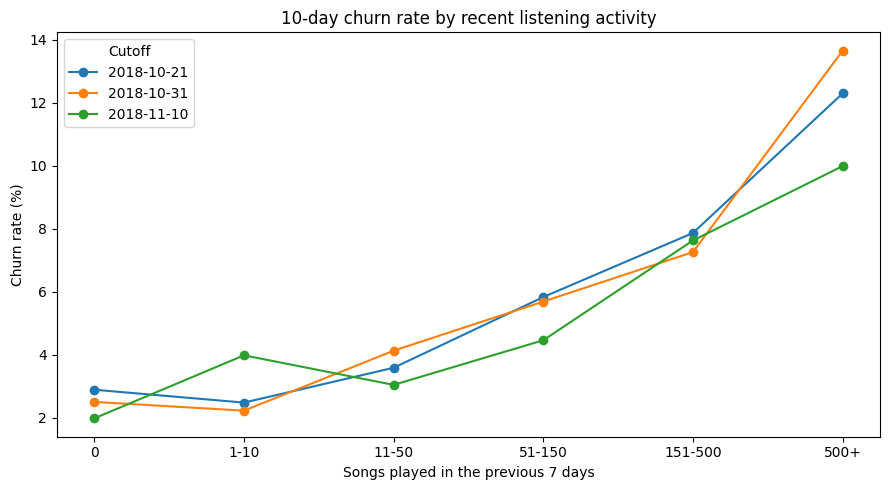

In [47]:
# Define listening activity categories
activity_bins = [-1, 0, 10, 50, 150, 500, np.inf]

activity_labels = [
    "0", "1-10", "11-50",
    "51-150", "151-500", "500+"
]

engagement["activity_group"] = pd.cut(
    engagement["songs_7d"],
    bins=activity_bins,
    labels=activity_labels
)

# Compute churn rates within activity groups
activity_summary = (
    engagement.groupby(
        ["cutoff", "activity_group"],
        observed=True
    )
    .agg(
        n_users=("userId", "size"),
        n_churners=("churn_10d", "sum"),
        churn_rate=("churn_10d", "mean")
    )
    .reset_index()
)

activity_summary["churn_rate_pct"] = (
    activity_summary["churn_rate"] * 100
)

display(activity_summary.round(2))

# Compare activity groups across historical cutoffs
plot_data = activity_summary.pivot(
    index="activity_group",
    columns="cutoff",
    values="churn_rate_pct"
).reindex(activity_labels)

ax = plot_data.plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

ax.set_title("10-day churn rate by recent listening activity")
ax.set_xlabel("Songs played in the previous 7 days")
ax.set_ylabel("Churn rate (%)")
ax.legend(title="Cutoff")

plt.tight_layout()
plt.show()

**Findings:** The results reveal a clear positive association between recent listening activity and subsequent churn across all three historical cutoffs.

Users who played more than 500 songs during the previous seven days exhibit churn rates ranging from **9.99% to 13.65%**, compared with only **1.98% to 2.89%** among users who played no songs. This represents approximately a four- to fivefold difference in churn risk.

Although the relationship is not strictly monotonic across all activity groups, the overall pattern remains consistent across observation periods. Moreover, the most active group contains several hundred users at each cutoff, suggesting that the observed differences are not driven by extremely small sample sizes.

We next investigate whether user satisfaction, measured through positive and negative feedback, is also associated with subsequent churn.

### User satisfaction and churn

Finally, we explore whether user feedback is associated with subsequent churn.

The platform records positive and negative feedback through `Thumbs Up` and `Thumbs Down` events.

Since highly active users have more opportunities to provide feedback, we normalize these interactions by the number of songs played during the previous seven days.

We investigate whether users expressing more negative feedback are more likely to cancel their subscriptions within the following 10 days.

,cutoff,churn_10d,n_users,mean_dislikes,median_dislikes,mean_likes
0,2018-10-21,0,9979,1.25,0.86,5.63
1,2018-10-21,1,680,1.41,1.02,5.11
2,2018-10-31,0,9500,1.23,0.86,5.62
3,2018-10-31,1,656,1.40,1.05,5.03
4,2018-11-10,0,9118,1.23,0.87,5.68
5,2018-11-10,1,538,1.53,1.03,5.08


,cutoff,dislike_group,n_users,n_churners,churn_rate,churn_rate_pct
0,2018-10-21,0,3543,139,0.04,3.92
1,2018-10-21,0-1,2283,190,0.08,8.32
2,2018-10-21,1-3,3688,276,0.07,7.48
3,2018-10-21,3+,1145,75,0.07,6.55
4,2018-10-31,0,3324,144,0.04,4.33
5,2018-10-31,0-1,2253,169,0.08,7.50
6,2018-10-31,1-3,3554,267,0.08,7.51
7,2018-10-31,3+,1025,76,0.07,7.41
8,2018-11-10,0,3201,103,0.03,3.22
9,2018-11-10,0-1,2071,161,0.08,7.77


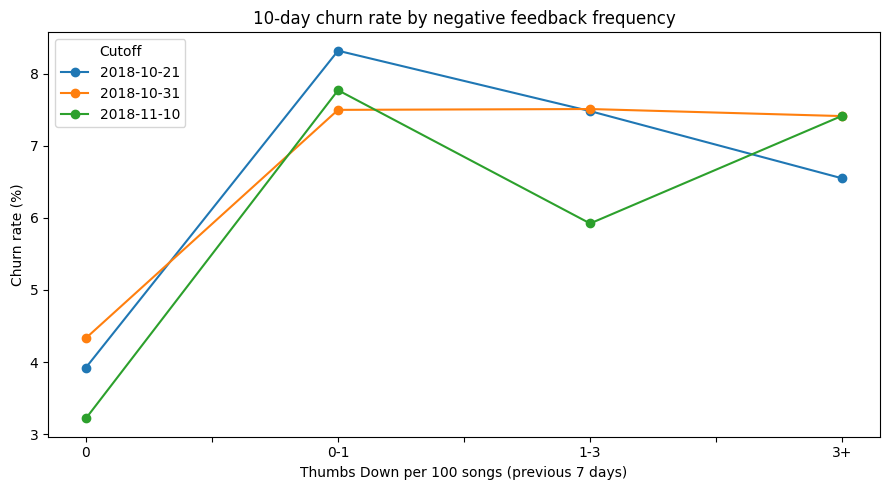

In [48]:
# Focus on users with sufficient recent listening activity to obtain more stable feedback ratios
active_users = engagement.loc[
    engagement["songs_7d"] >= 10
].copy()

# Normalize feedback by listening activity
active_users["down_per_100_songs"] = (
    100 * active_users["thumbs_down_7d"]
    / active_users["songs_7d"]
)

active_users["up_per_100_songs"] = (
    100 * active_users["thumbs_up_7d"]
    / active_users["songs_7d"]
)

# Compare normalized feedback by churn status
satisfaction_summary = (
    active_users.groupby(
        ["cutoff", "churn_10d"],
        as_index=False
    )
    .agg(
        n_users=("userId", "size"),
        mean_dislikes=("down_per_100_songs", "mean"),
        median_dislikes=("down_per_100_songs", "median"),
        mean_likes=("up_per_100_songs", "mean")
    )
)

display(satisfaction_summary.round(2))

# Group users by negative feedback frequency
dislike_labels = ["0", "0-1", "1-3", "3+"]

active_users["dislike_group"] = pd.cut(
    active_users["down_per_100_songs"],
    bins=[-0.01, 0, 1, 3, np.inf],
    labels=dislike_labels
)

# Compute churn rates by negative feedback group
dislike_summary = (
    active_users.groupby(
        ["cutoff", "dislike_group"],
        observed=True
    )
    .agg(
        n_users=("userId", "size"),
        n_churners=("churn_10d", "sum"),
        churn_rate=("churn_10d", "mean")
    )
    .reset_index()
)

dislike_summary["churn_rate_pct"] = (
    100 * dislike_summary["churn_rate"]
)

display(dislike_summary.round(2))

# Visualize the relationship with churn
plot_data = dislike_summary.pivot(
    index="dislike_group",
    columns="cutoff",
    values="churn_rate_pct"
).reindex(dislike_labels)

ax = plot_data.plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

ax.set_title("10-day churn rate by negative feedback frequency")
ax.set_xlabel("Thumbs Down per 100 songs (previous 7 days)")
ax.set_ylabel("Churn rate (%)")
ax.legend(title="Cutoff")

plt.tight_layout()
plt.show()

**Findings:** Across the three historical cutoffs, future churners consistently exhibit slightly higher negative feedback rates and lower positive feedback rates than non-churners.

Users who expressed no negative feedback during the previous seven days show substantially lower churn rates (3.22–4.33%) than users who expressed at least one `Thumbs Down`.

However, the relationship is not monotonic: higher frequencies of negative feedback do not systematically correspond to higher churn rates.

These results suggest that the **presence of negative feedback may be more informative than its intensity**, making both the number of `Thumbs Down` events and a binary indicator of negative feedback potentially useful features.

This analysis only includes users who played at least 10 songs during the preceding seven days. Moreover, the observed associations may be influenced by other user characteristics, such as listening activity or subscription level.

Therefore, the actual predictive value of these indicators will need to be evaluated during model training and validation.

## Key findings and implications for feature engineering

Our exploratory data analysis provides several insights into user behavior and its potential relationship with subscription cancellations.

1) Dataset structure and user behavior

The training dataset contains approximately 17.5 million events generated by 19,140 users. Each user can generate multiple events, highlighting the need to aggregate event-level data into user-level features.

Missing values in song, artist, and length are associated with non-music-related events and therefore do not necessarily represent data quality issues.

2. Subscription levels and cancellations

Our analysis reveals that users can interact with the platform under different subscription levels (free and paid). Over 10,000 users have events associated with both levels during the observation period.

We also explored subscription downgrades and cancellations. These behaviors could provide useful predictive information, provided that only events occurring before each prediction cutoff are considered.

3. Churn definition and class imbalance

Overall, 4,271 training users (approximately 22.3%) cancelled their subscriptions during the observation period. However, when considering a 10-day prediction horizon, the churn rate falls to approximately 4–5% of eligible users across our three historical cutoffs.

This highlights the class imbalance in our prediction task and supports the use of balanced accuracy as the evaluation metric.

4. Engagement and satisfaction

Contrary to our initial intuition, future churners consistently exhibit higher recent listening activity than non-churners. Users playing more than 500 songs during the previous seven days show substantially higher churn rates than inactive users.

Negative feedback also appears associated with subsequent churn. Users who express no Thumbs Down generally exhibit lower cancellation rates, although the relationship is not strictly monotonic.

These relationships remain descriptive and do not establish causality or predictive performance.

### Implications for preprocessing

Based on these findings, we will consider several families of features:

- Engagement: listening volume, number of sessions, and recent activity.

- Satisfaction: positive and negative feedback, including activity-normalized ratios.

- Subscription behavior: current subscription level and previous upgrades or downgrades.

- User characteristics: account tenure and other potentially relevant information.

The preprocessing stage will transform the raw event logs into user-level observations at different historical cutoffs. All features will be computed using only information available before each cutoff, while the target will indicate whether the user cancels within the following 10 days.

The predictive value of these features will subsequently be assessed through model training and validation.